<a href="https://colab.research.google.com/github/M-Aparecida/questao5_atividadeRNN/blob/main/Quest%C3%A3o_5_Atividade_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb

In [2]:
vocab_size = 10000
seq_length = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Treinamento:", len(x_train))
print("Teste:", len(x_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Treinamento: 25000
Teste: 25000


In [3]:
x_train = pad_sequences(x_train, maxlen=seq_length)
x_test = pad_sequences(x_test, maxlen=seq_length)

In [4]:
model = Sequential([
    Input(shape=(seq_length,)),
    Embedding(vocab_size, 64),
    LSTM(50, return_sequences=False),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50)             │        23,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 663,051 (2.53 MB)

 Trainable params: 663,051 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 128ms/step - accuracy: 0.7929 - loss: 0.4409 - val_accuracy: 0.8686 - val_loss: 0.3233
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 125ms/step - accuracy: 0.8927 - loss: 0.2707 - val_accuracy: 0.8688 - val_loss: 0.3340
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 123ms/step - accuracy: 0.9219 - loss: 0.2056 - val_accuracy: 0.8682 - val_loss: 0.3481


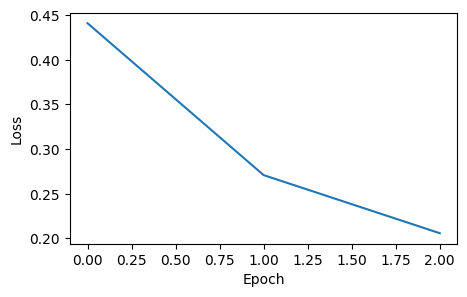

In [7]:
plt.figure(figsize=(5,3))
plt.plot(history.history['loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [9]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Loss:", loss)
print("Acurácia:", accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 22ms/step - accuracy: 0.8553 - loss: 0.3726
Loss: 0.37257418036460876
Acurácia: 0.8553199768066406


(b) Acurácia final:
85,53%

(c) Por que LSTMs funcionam melhor que RNNs simples em textos longos?

As LSTMs possuem portas que controlam quais informações devem ser mantidas ou descartadas, permitindo armazenar informações importantes por mais tempo. Assim, reduzem o problema do gradiente desaparecido e conseguem aprender dependências de longo prazo, sendo mais eficientes no processamento de textos longos.